<a href="https://colab.research.google.com/github/eltilinpro68/Programacion-para-IA/blob/main/Actividad_Fundamental_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PpIA: Actividad fundamental 3 - Ejercicio de Árbol de Decisión
**Integrantes:**

Aldo Maximiliano Murillo Botello 2205993

Mario Ezequiel Verdugo Gordillo 2276504

Angel Fernando Munguia Felix 2276311

Dylan Andre Macías Martinez 2208139

Angel Tadeo Correa Torres 1905525

**Descripción de la lógica general:**
En esta libreta implementamos un sistema completo de Machine Learning para predecir la aparición de diabetes utilizando un árbol de decisión. El proceso incluye la carga del dataset público *Pima Indians Diabetes*, un análisis exploratorio de los datos (EDA), limpieza avanzada (imputación de valores faltantes mediante la mediana condicionada y eliminación de atípicos con el rango intercuartílico), y finalmente el entrenamiento, evaluación y graficado del modelo clasificatorio.

### 1. Carga del Dataset
**Lógica implementada:**
Se importan las librerías necesarias para el manejo de datos (Pandas, NumPy), visualización (Matplotlib) y modelado (Scikit-Learn). Posteriormente, se carga el conjunto de datos directamente desde un repositorio público, asignando los nombres correctos a cada columna biológica según la documentación médica, y se imprimen las primeras filas para verificar su correcta estructura en memoria.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report

# 1. Carga del Dataset
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
columnas = [
    'Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness',
    'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'
]

df = pd.read_csv(url, header=None, names=columnas)
print("--- Primeras filas del dataset original ---")
print(df.head())
print("\n" + "="*50 + "\n")

--- Primeras filas del dataset original ---
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  




### 2. Análisis Exploratorio y Visualización
**Lógica implementada:**
Utilizamos métodos nativos de Pandas (`describe()` e `info()`) para obtener un resumen estadístico completo y detectar posibles anomalías iniciales en los tipos de datos. Adicionalmente, se genera un diagrama de dispersión para observar la relación directa entre la Concentración de Glucosa y el Índice de Masa Corporal (BMI), diferenciando de manera visual y mediante etiquetas a los pacientes sanos de los que padecen diabetes.

--- Resumen estadístico completo ---
       Pregnancies     Glucose  BloodPressure  SkinThickness     Insulin  \
count   768.000000  768.000000     768.000000     768.000000  768.000000   
mean      3.845052  120.894531      69.105469      20.536458   79.799479   
std       3.369578   31.972618      19.355807      15.952218  115.244002   
min       0.000000    0.000000       0.000000       0.000000    0.000000   
25%       1.000000   99.000000      62.000000       0.000000    0.000000   
50%       3.000000  117.000000      72.000000      23.000000   30.500000   
75%       6.000000  140.250000      80.000000      32.000000  127.250000   
max      17.000000  199.000000     122.000000      99.000000  846.000000   

              BMI  DiabetesPedigreeFunction         Age     Outcome  
count  768.000000                768.000000  768.000000  768.000000  
mean    31.992578                  0.471876   33.240885    0.348958  
std      7.884160                  0.331329   11.760232    0.476951 

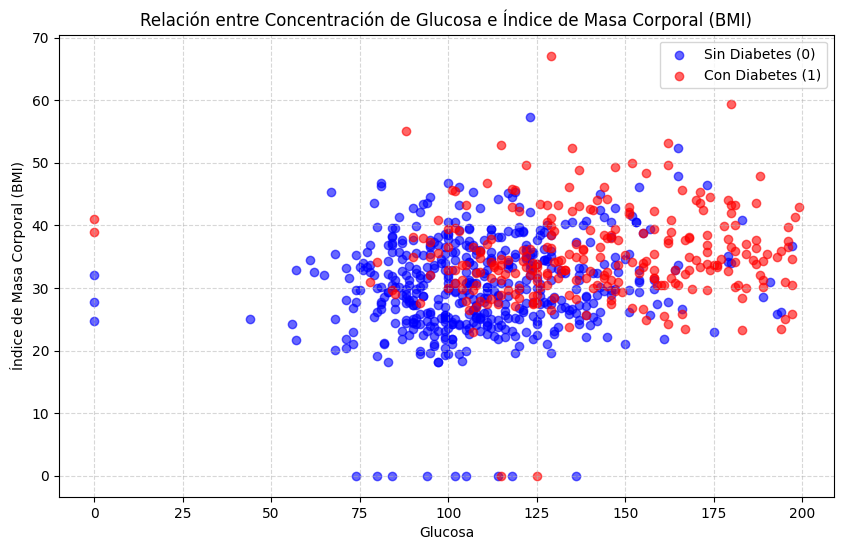

In [ ]:
# 2. Análisis Exploratorio y Visualización
print("--- Resumen estadístico completo ---")
print(df.describe())

print("\n--- Información general y valores nulos ---")
print(df.info())

# Visualización: Diagrama de Dispersión (Glucose vs BMI por Outcome)
plt.figure(figsize=(10, 6))

sin_diabetes = df[df['Outcome'] == 0]
con_diabetes = df[df['Outcome'] == 1]

plt.scatter(sin_diabetes['Glucose'], sin_diabetes['BMI'], color='blue', alpha=0.6, label='Sin Diabetes (0)')
plt.scatter(con_diabetes['Glucose'], con_diabetes['BMI'], color='red', alpha=0.6, label='Con Diabetes (1)')

plt.title('Relación entre Concentración de Glucosa e Índice de Masa Corporal (BMI)')
plt.xlabel('Glucosa')
plt.ylabel('Índice de Masa Corporal (BMI)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### 3. Limpieza y Preprocesamiento de Datos
**Lógica implementada:**
Primero se identifican ceros "encubiertos" en variables vitales que biológicamente no pueden ser cero (como presión o insulina) y se reemplazan por `NaN`. A continuación, para no perder registros, imputamos esos nulos con la mediana calculada dinámicamente según la clase del paciente (con o sin diabetes). Finalmente, aplicamos la técnica estadística del Rango Intercuartílico (IQR) para delimitar las fronteras normales en la variable de Insulina, filtrando y eliminando los valores atípicos severos.

In [ ]:
# 3. Limpieza y Preprocesamiento de Datos

# Detección de nulos encubiertos
cols_biologicas = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
df[cols_biologicas] = df[cols_biologicas].replace(0, np.nan)

# Imputación condicional: mediana por grupo de 'Outcome' (Con / Sin Diabetes)
for col in cols_biologicas:
    df[col] = df.groupby('Outcome')[col].transform(lambda group: group.fillna(group.median()))

# Tratamiento de valores atípicos (Outliers) en 'Insulin' por IQR
q25, q75 = np.percentile(df['Insulin'], [25, 75])
iqr = q75 - q25
limite_inferior = q25 - (1.5 * iqr)
limite_superior = q75 + (1.5 * iqr)

df_limpio = df[(df['Insulin'] >= limite_inferior) & (df['Insulin'] <= limite_superior)].copy()

print("\n--- Tamaño del dataset ---")
print(f"Original: {df.shape[0]} muestras | Tras eliminar outliers de Insulin: {df_limpio.shape[0]} muestras\n")


--- Tamaño del dataset ---
Original: 768 muestras | Tras eliminar outliers de Insulin: 717 muestras



### 4. Entrenamiento y Evaluación del Árbol de Decisión
**Lógica implementada:**
Se prepara la matriz independiente (`X`) y la etiqueta a predecir (`y`), dividiendo la información 75/25 para entrenamiento y prueba. Fijamos una semilla (`random_state=42`) para garantizar reproductibilidad y usamos estratificación para que ambas divisiones representen equitativamente las clases. Por último, entrenamos un Árbol de Decisión acotando su profundidad a 3 (para prevenir sobreajuste), imprimimos métricas de desempeño detalladas (Exactitud, Precisión y Recall) y representamos la arquitectura final del árbol usando `plot_tree`.

Exactitud (Accuracy): 0.8944

--- Reporte de Clasificación ---
              precision    recall  f1-score   support

Sin Diabetes       0.93      0.91      0.92       120
Con Diabetes       0.83      0.87      0.85        60

    accuracy                           0.89       180
   macro avg       0.88      0.89      0.88       180
weighted avg       0.90      0.89      0.90       180



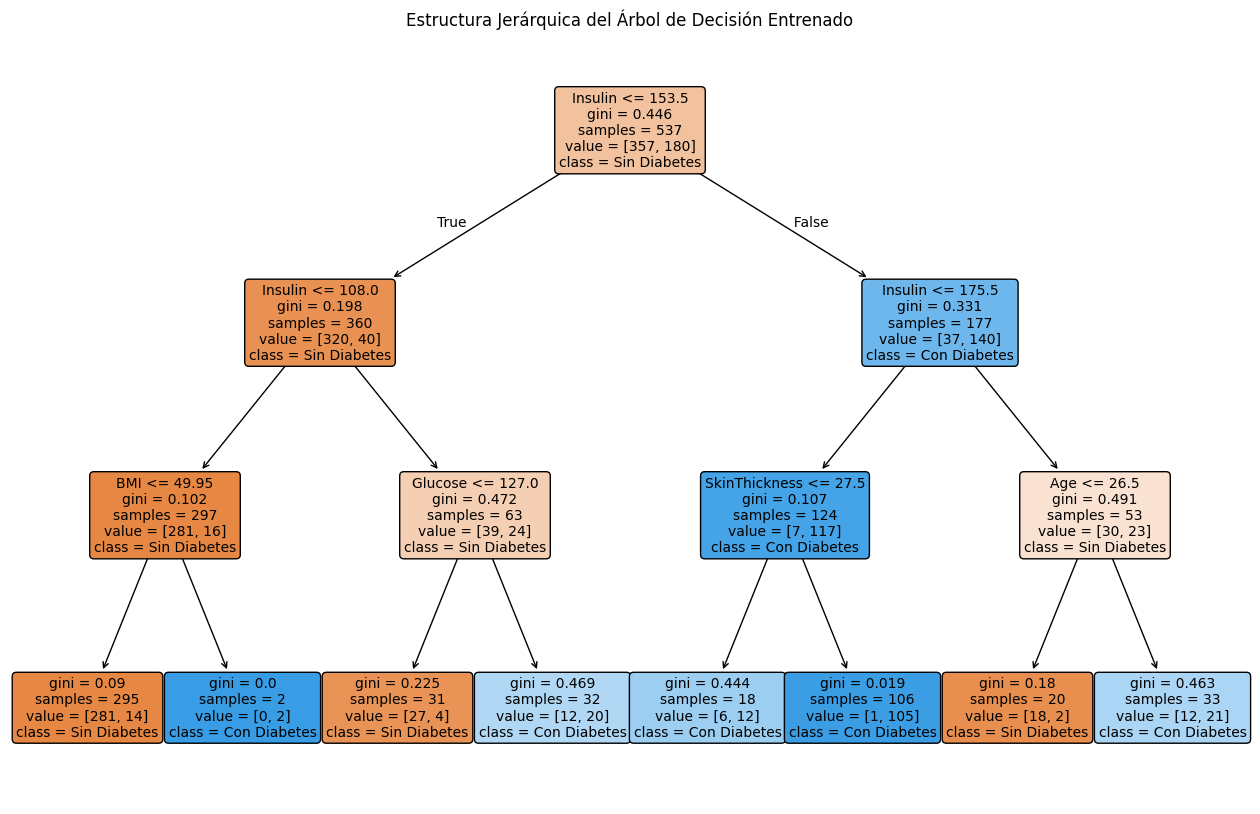

In [ ]:
# 4. Entrenamiento y Evaluación del Árbol de Decisión

X = df_limpio.drop(columns=['Outcome'])
y = df_limpio['Outcome']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

modelo = DecisionTreeClassifier(max_depth=3, random_state=42)
modelo.fit(X_train, y_train)

y_pred = modelo.predict(X_test)
exactitud = accuracy_score(y_test, y_pred)

print(f"Exactitud (Accuracy): {exactitud:.4f}\n")
print("--- Reporte de Clasificación ---")
print(classification_report(y_test, y_pred, target_names=['Sin Diabetes', 'Con Diabetes']))

# Visualización de la Estructura del Árbol
plt.figure(figsize=(16, 10))
plot_tree(
    modelo,
    feature_names=X.columns,
    class_names=['Sin Diabetes', 'Con Diabetes'],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Estructura Jerárquica del Árbol de Decisión Entrenado")
plt.show()